In [2]:
import numpy as np
import matplotlib.pyplot as plt

from calibration import optimal_petz_calibration
from robustness import mismatched_petz_fidelity

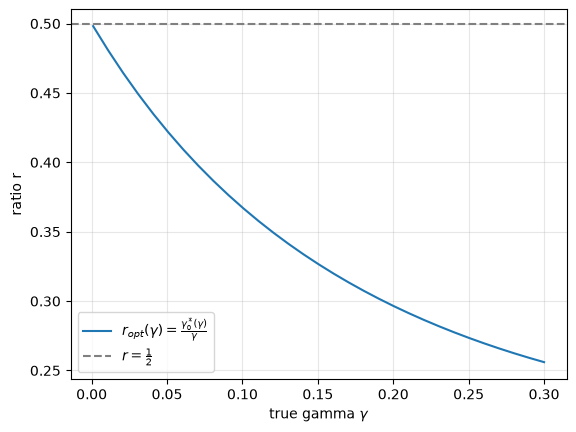

In [2]:
gamma = np.linspace(0.001, 0.3, 31)

opti = [optimal_petz_calibration(gam)[0] for gam in gamma]
ratio = [opti[k]/gamma[k] for k in range(len(gamma))]
gain = [mismatched_petz_fidelity(gamma[k], opti[k])-mismatched_petz_fidelity(gamma[k], gamma[k]) for k in range(len(gamma))]

plt.plot(gamma, ratio, label=r"$r_{opt}(\gamma)=\frac{\gamma_{0}^*(\gamma)}{\gamma}$")
plt.axhline(0.5, color="gray", linestyle="--", label=r"$r = \frac{1}{2}$")
plt.xlabel(r"true gamma $\gamma$")
plt.ylabel(r"ratio r")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../figures/optimal_calibration_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

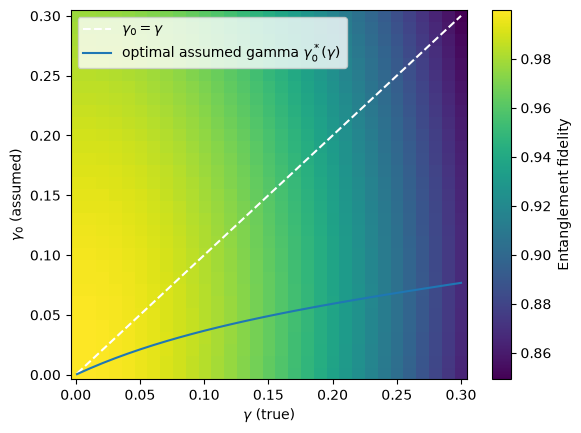

In [3]:
gamma_0= np.linspace(0.001, 0.3, 31)

F = np.array([[mismatched_petz_fidelity(g, g0) for g in gamma] for g0 in gamma_0])

plt.pcolormesh(gamma, gamma_0, F, shading="auto")
plt.colorbar(label="Entanglement fidelity")
plt.plot(gamma, gamma_0, "w--", label=r"$\gamma_0 = \gamma$")   # matched diagonal
plt.plot(gamma, opti, label = r"optimal assumed gamma $\gamma_0^*(\gamma)$")
plt.xlabel(r"$\gamma$ (true)")
plt.ylabel(r"$\gamma_0$ (assumed)")
plt.legend()
plt.savefig("../figures/optimal_calibration_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

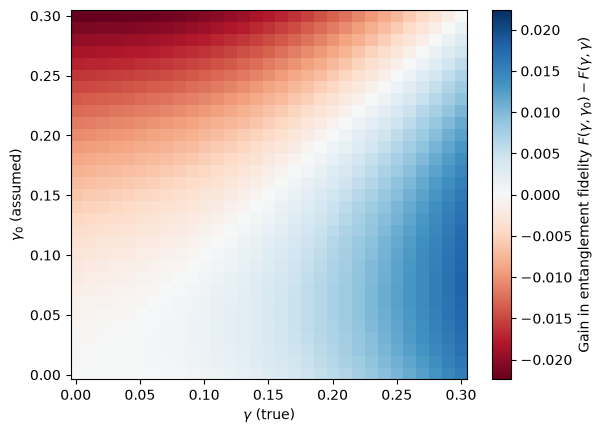

In [4]:
D = np.array([[mismatched_petz_fidelity(g, g0)-mismatched_petz_fidelity(g, g) for g in gamma] for g0 in gamma_0])

m = np.abs(D).max()
plt.pcolormesh(gamma, gamma_0, D, shading="auto", cmap="RdBu", vmin=-m, vmax=m)
plt.colorbar(label=r"Gain in entanglement fidelity $F(\gamma, \gamma_0) - F(\gamma, \gamma)$")
plt.xlabel(r"$\gamma$ (true)")
plt.ylabel(r"$\gamma_0$ (assumed)")
plt.savefig("../figures/fidelity_gain_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

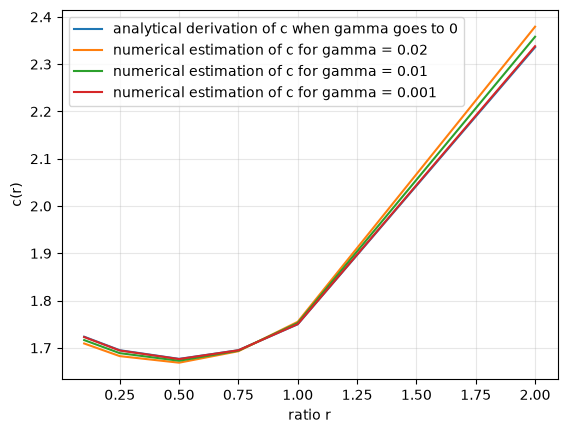

In [ ]:
gammas = [0.02, 0.01, 0.001]
ratios = [0.1, 0.25, 0.5, 0.75, 1.0, 2.0]
c_analytical = [7/4 + (1-1/np.sqrt(2))*r*(r-1) for r in ratios]
c_est = lambda gam :  [(1 - mismatched_petz_fidelity(gam, r*gam)) / gam**2 for r in ratios ]

plt.plot(ratios, c_analytical, label=r"analytical derivation of c when gamma goes to 0")
plt.plot(ratios, c_est(0.02), label=r"numerical estimation of c for gamma = 0.02")
plt.plot(ratios, c_est(0.01), label=r"numerical estimation of c for gamma = 0.01")
plt.plot(ratios, c_est(0.001), label=r"numerical estimation of c for gamma = 0.001")

plt.xlabel(r"ratio r")
plt.ylabel(r"c(r)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

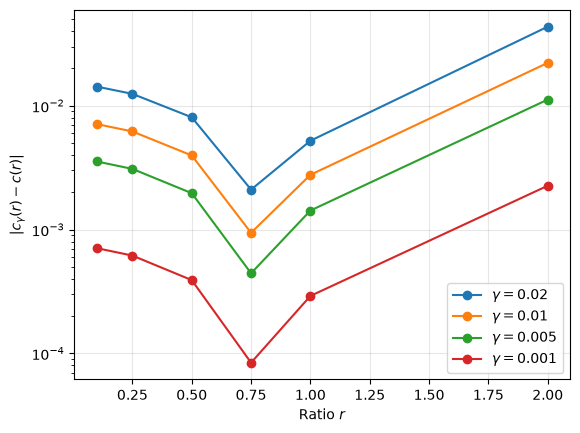

In [10]:
for g in [0.02, 0.01, 0.005, 0.001]:
    error = np.abs(np.array(c_est(g)) - np.array(c_analytical))
    plt.plot(ratios, error, "o-", label=fr"$\gamma={g}$")

plt.xlabel(r"Ratio $r$")
plt.ylabel(r"$|c_\gamma(r)-c(r)|$")
plt.yscale("log")
plt.legend()
plt.grid(alpha=0.3)
plt.show()